# Pendahuluan

Di dalam material ini, kamu akan mempelajari Data Heart Disease dan belajar bagaimana dilakukan elaborasi. Lakukan kode dan jalankan setiap sel. Selama proses pembelajaran, kamu akan menemui beberapa blok **TODO** -- ikuti petunjuk untuk mengisinya sebelum menjalankan sel-sel tersebut dan melanjutkan.

## Introduction to Capstone Project

Adult/Census Income merupakan dataset klasifikasi yang digunakan untuk memprediksi apakah pendapatan tahunan seseorang berada pada kategori <=50K atau >50K berdasarkan karakteristik demografis, pendidikan, pekerjaan, dan kondisi ekonomi yang tersedia. Informasi ini dapat digunakan untuk memahami pola yang berhubungan dengan tingkat pendapatan serta membantu proses analisis dan segmentasi data secara lebih terukur.
Tujuan bisnis yang ingin dicapai adalah membangun model prediksi kelas pendapatan yang mampu mengklasifikasikan data baru secara konsisten berdasarkan fitur-fitur yang tersedia. Model ini diharapkan dapat membantu proses analisis dalam memahami karakteristik kelompok pendapatan rendah dan tinggi, sehingga dapat menjadi pendukung dalam penyusunan strategi atau kebijakan yang lebih tepat sasaran.
Karena dataset ini berasal dari data sensus historis, hasil prediksi tidak boleh digunakan sebagai satu-satunya dasar untuk keputusan pekerjaan, kredit, bantuan sosial, atau keputusan lain yang berdampak langsung pada seseorang. Model digunakan untuk kebutuhan pembelajaran, analisis, dan demonstrasi machine learning dengan tetap memperhatikan evaluasi performa, bias, fairness, dan privasi data.

**Problem Statement**

Masalah yang ingin diselesaikan adalah membangun model klasifikasi yang dapat memprediksi apakah pendapatan tahunan seseorang berada pada kategori <=50K atau >50K berdasarkan karakteristik demografis, pendidikan, pekerjaan, dan kondisi ekonomi yang tersedia dalam dataset.

**About Datasets**

Dataset yang digunakan adalah data Adult/Census Income yang diunduh dari Kaggle

Dataset yang digunakan ini berasal dari data sensus tahun 1994. Dataset ini berisi informasi demografis, pendidikan, pekerjaan, dan kondisi ekonomi seseorang. Bidang `income` digunakan sebagai target untuk memprediksi apakah pendapatan tahunan seseorang berada pada kategori `<=50K` atau `>50K`.

Dataset Adult yang digunakan terdiri dari 32.561 baris data dan 14 atribut + 1 target. Dataset ini memiliki 15 kolom yaitu:

1. `age`: variabel ini merepresentasikan usia seseorang yang diukur dalam tahun.
2. `workclass`: variabel ini merepresentasikan kelas atau jenis status pekerjaan seseorang.
3. `fnlwgt`: variabel ini merepresentasikan bobot sensus.
4. `education`: variabel ini merepresentasikan tingkat pendidikan terakhir seseorang.
5. `education.num`: variabel ini merepresentasikan tingkat pendidikan dalam bentuk numerik.
6. `marital.status`: variabel ini merepresentasikan status pernikahan seseorang.
7. `occupation`: variabel ini merepresentasikan jenis pekerjaan seseorang.
8. `relationship`: variabel ini merepresentasikan hubungan seseorang dalam keluarga.
9. `race`: variabel ini merepresentasikan kelompok ras seseorang.
10. `sex`: variabel ini merepresentasikan jenis kelamin seseorang.
11. `capital.gain`: variabel ini merepresentasikan keuntungan modal yang diperoleh seseorang.
12. `capital.loss`: variabel ini merepresentasikan kerugian modal yang dialami seseorang.
13. `hours.per.week`: variabel ini merepresentasikan jumlah jam kerja seseorang dalam satu minggu.
14. `native.country`: variabel ini merepresentasikan negara asal seseorang.
15. `income`: variabel target yang merepresentasikan kategori pendapatan tahunan seseorang. Nilai `<=50K` menunjukkan pendapatan kurang dari atau sama dengan 50 ribu dolar, sedangkan nilai `>50K` menunjukkan pendapatan lebih dari 50 ribu dolar.


**Objective of Capstone 1**

Tujuan dari Capstone adalah melakukan data preprocessing termasuk Exploratory Data Analysis untuk menggali insight dari dataset Adult/Census Income. Analisis dilakukan untuk memahami karakteristik individu berdasarkan pendapatan tahunan, seperti usia, tingkat pendidikan, kelas pekerjaan, jenis pekerjaan, status pernikahan, jenis kelamin, jam kerja per minggu, keuntungan modal, dan negara asal.
Hasil akhir yang ingin dicapai yaitu mendapatkan insight mengenai karakteristik kelompok pendapatan <=50K dan >50K, memperoleh data yang sudah bersih dan siap dimodelkan, serta menentukan fitur dan preprocessing yang sesuai untuk tahap modeling selanjutnya.

**Metrics**

Tahap untuk mendukung dalam menyelesaikan problem statement yang ada dan akan digunakan untuk memantau hasil analisis. Berikut metrics yang termasuk:

1. Jumlah dan proporsi individu pada kategori pendapatan `<=50K` dan `>50K`.
2. Rata-rata usia, tingkat pendidikan, dan jam kerja per minggu berdasarkan kategori pendapatan.
3. Proporsi jenis kelamin, kelas pekerjaan, dan tingkat pendidikan pada masing-masing kategori pendapatan.
4. Korelasi target pendapatan terhadap variabel numerik yang ada pada dataset, seperti usia, `education.num`, `capital.gain`, `capital.loss`, dan `hours.per.week`.


**Persiapan**

Disini kita akan menyiapkan libraries yang diperlukan dan dataset berdasarkan link:
Dalam rangka mengetahui tentang dataset, kita akan melihat overview.

In [45]:
# Import libraries
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [46]:
# Memuat dataset Adult
data = pd.read_csv("adult.csv")

# Menampilkan lima baris teratas
data.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [47]:
# Menampilkan lima baris terbawah
data.tail()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [48]:
# Jumlah baris dan kolom
data.shape

(32561, 15)

In [49]:
# Nama kolom
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='str')

In [50]:
# Persebaran data numerik
data.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [51]:
# Jumlah nilai unik semua kolom
data.nunique()

age                  73
workclass             9
fnlwgt            21648
education            16
education.num        16
marital.status        7
occupation           15
relationship          6
race                  5
sex                   2
capital.gain        119
capital.loss         92
hours.per.week       94
native.country       42
income                2
dtype: int64

In [52]:
# Informasi dataframe
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


**Data Quality**

Disini kita akan melakukan pengecekan karakter, handling missing value, outlier, duplikat dan data imbalance serta skewness.

In [53]:
# Melakukan handling kolom menjadi kategorikal
lst = ['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income']
data[lst] = data[lst].astype(object)

# Melihat perubahan
data.dtypes

age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
dtype: object

In [54]:
# Pisahkan numerical dan categorical
numerical_col = data.select_dtypes(exclude=object)
categorical_col = data.select_dtypes(include=object)

print("Numerik   :", list(numerical_col.columns))
print("Kategorik :", list(categorical_col.columns))

Numerik   : ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Kategorik : ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']


In [55]:
# Pengecekan karakter dari data kategorikal
for i in categorical_col:
    print("Berikut ini merupakan informasi: {} dengan {}".format(i, data[i].unique()))
    print()

Berikut ini merupakan informasi: workclass dengan ['?' 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']

Berikut ini merupakan informasi: education dengan ['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']

Berikut ini merupakan informasi: marital.status dengan ['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']

Berikut ini merupakan informasi: occupation dengan ['?' 'Exec-managerial' 'Machine-op-inspct' 'Prof-specialty'
 'Other-service' 'Adm-clerical' 'Craft-repair' 'Transport-moving'
 'Handlers-cleaners' 'Sales' 'Farming-fishing' 'Tech-support'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

Berikut ini merupakan informasi: relationship dengan ['Not-in-family' 'Unmarried' 'Own-child' 'Other-relative' 'Husband' 'Wife']

Berikut ini m

In [56]:
print((data == "?").sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [57]:
data = data.replace("?", np.nan)

Selanjutnya kita akan handling missing value.

In [58]:
# Check missing values
print("Hasil missing value:\n", data.isnull().sum())

Hasil missing value:
 age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [59]:
# Fillna pada kolom nan dengan modus
modus_workclass = data['workclass'].mode()[0]
data['workclass'] = data['workclass'].fillna(modus_workclass)

modus_occupation = data['occupation'].mode()[0]
data['occupation'] = data['occupation'].fillna(modus_occupation)

modus_country = data['native.country'].mode()[0]
data['native.country'] = data['native.country'].fillna(modus_country)

print("Modus workclass     :", modus_workclass)
print("Modus occupation    :", modus_occupation)
print("Modus native.country:", modus_country)

Modus workclass     : Private
Modus occupation    : Prof-specialty
Modus native.country: United-States


In [60]:
# Check missing values kembali
print("Hasil missing value:\n", data.isnull().sum())

Hasil missing value:
 age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64


Kita akan melakukan pengecekan rows yang duplikat.

In [61]:
# Memeriksa duplikat data
data.duplicated().sum()

np.int64(24)

In [62]:
# Menampilkan baris data duplicate
data[data.duplicated()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
8453,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
8645,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
12202,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
14346,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
15603,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K
17344,21,Private,243368,Preschool,1,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,50,Mexico,<=50K
19067,46,Private,173243,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
20388,30,Private,144593,HS-grad,9,Never-married,Other-service,Not-in-family,Black,Male,0,0,40,United-States,<=50K
20507,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
22783,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K


Berdasarkan output diatas, kamu perlu melakukan drop duplikat data agar tidak ada data yang duplikat dalam dataset.

In [63]:
# Menghapus data duplikat
data.drop_duplicates(keep='first', inplace=True)

# Memeriksa ulang duplikat data
data.duplicated().sum()

np.int64(0)

Selanjutnya kita akan menampilkan outliers dan menghapus data yang outlier.

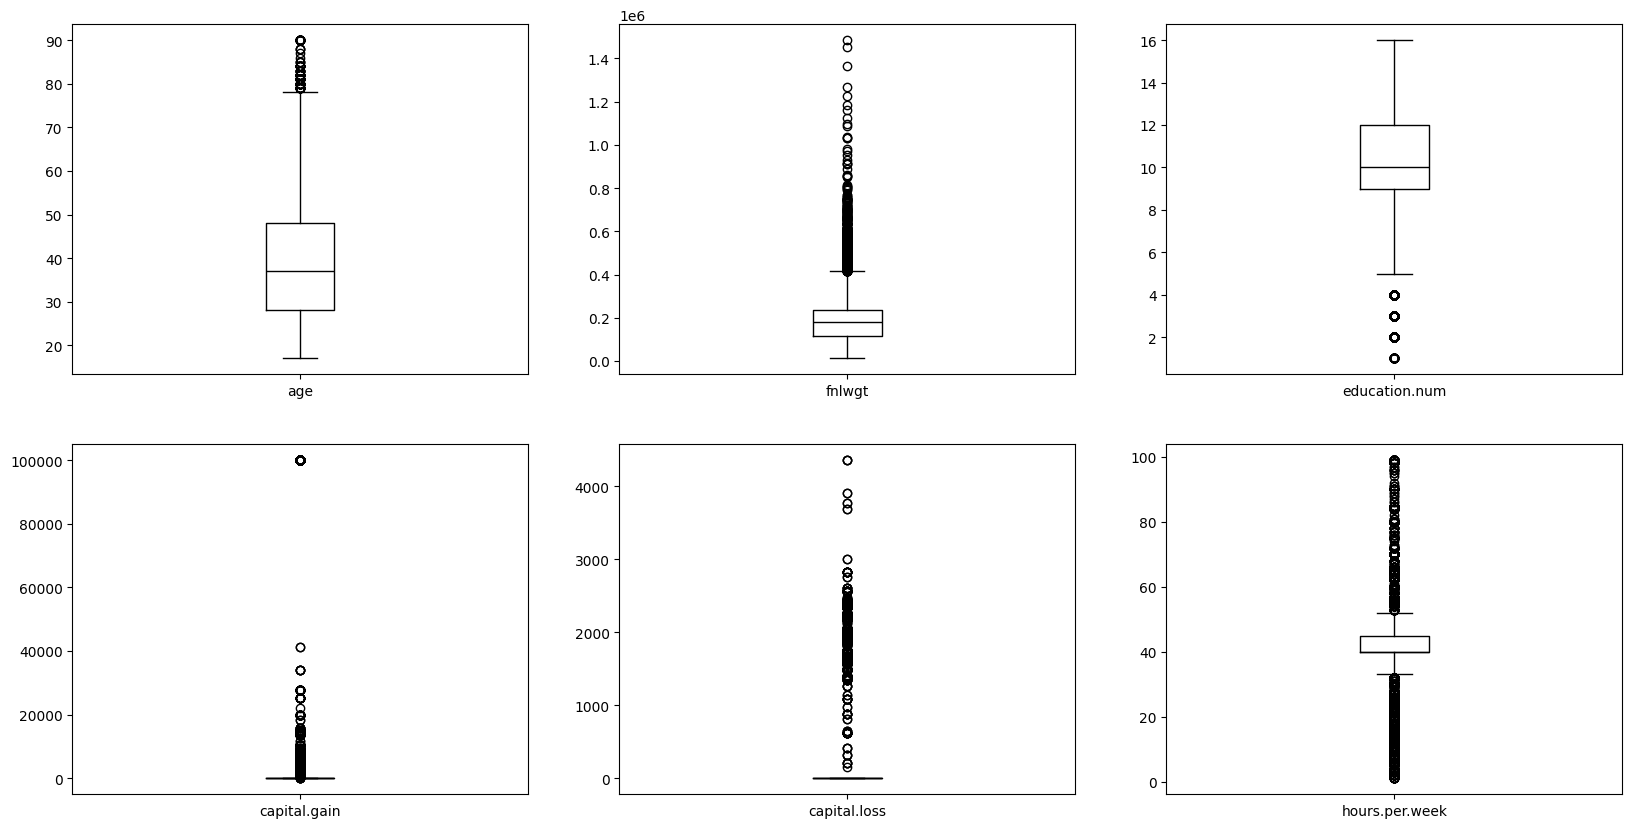

In [64]:
#Menampilkan boxplot untuk melihat outliers data numerik
numerical_col = data.select_dtypes(exclude=object)
categorical_col = data.select_dtypes(include=object)
numerical_col.plot(kind='box', subplots=True, layout=(2,3), sharex=False, sharey=False, figsize=(20, 10), color='k')
plt.show()

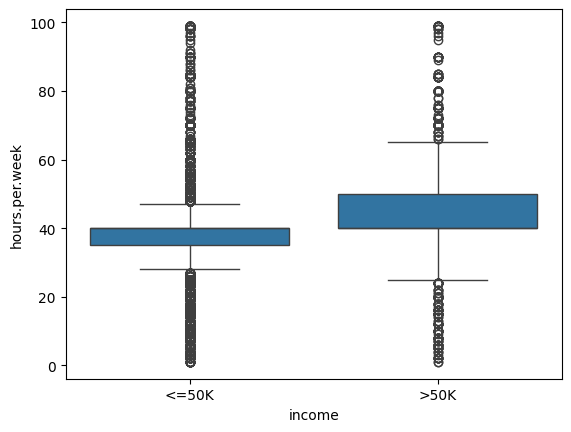

In [65]:
# Menampilkan data berdasarkan target untuk feature chol
sns.boxplot(x='income', y='hours.per.week', data=data)
plt.show()

Berdasarkan boxplot dan perhitungan IQR, outlier terdeteksi pada seluruh fitur numerik: 'age' (142), 'fnlwgt' (993), 'education.num' (1193), 'capital.gain' (2712), 'capital.loss' (1519), dan 'hours.per.week' (9002).

In [66]:
#Mencari tahu data yang outliers dengan mendefinisikan fungsi
continous_features = ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

def outliers(data_out, drop = False):
    for each_feature in data_out.columns:
        feature_data = data_out[each_feature]
        Q1 = np.percentile(feature_data, 25.)
        Q3 = np.percentile(feature_data, 75.)
        IQR = Q3-Q1
        outlier_step = IQR * 1.5
        outliers = feature_data[~((feature_data >= Q1 - outlier_step) & (feature_data <= Q3 + outlier_step))].index.tolist()
        if not drop:
            print('For the feature {}, Num of Outliers is {}'.format(each_feature, len(outliers)))
        if drop:
            data.drop(outliers, inplace = True, errors = 'ignore')
            print('Outliers from {} feature removed'.format(each_feature))

outliers(data[continous_features])

For the feature age, Num of Outliers is 142
For the feature fnlwgt, Num of Outliers is 993
For the feature education.num, Num of Outliers is 1193
For the feature capital.gain, Num of Outliers is 2712
For the feature capital.loss, Num of Outliers is 1519
For the feature hours.per.week, Num of Outliers is 9002


In [67]:
idx = set()
for f in continous_features:
    Q1, Q3 = np.percentile(data[f], [25, 75])
    step = (Q3 - Q1) * 1.5
    idx |= set(data[(data[f] < Q1 - step) | (data[f] > Q3 + step)].index)

print("Baris unik yang terdeteksi outlier:", len(idx), "dari", len(data))

Baris unik yang terdeteksi outlier: 13554 dari 32537


In [68]:
print(data.groupby(data['capital.gain'] > 0)['income'].value_counts(normalize=True))

capital.gain  income
False         <=50K     0.793395
              >50K      0.206605
True          >50K      0.618363
              <=50K     0.381637
Name: proportion, dtype: float64


**Keputusan Penanganan Outlier**

Berdasarkan metode IQR, outlier terdeteksi pada seluruh fitur numerik. Namun, data outlier **tidak dihapus** dengan pertimbangan berikut:

1. **'capital.gain' (2712 outlier) dan 'capital.loss' (1519 outlier):** sebagian besar nilainya 0, sehingga Q1 = Q3 = 0 dan IQR = 0. Akibatnya setiap nilai yang tidak 0 otomatis terdeteksi sebagai outlier. Nilai tersebut bukan kesalahan data, melainkan kelompok responden yang memang memiliki capital gain atau loss. Kelompok ini justru informatif: 61,8% responden dengan capital gain > 0 berpenghasilan >50K, sedangkan pada responden dengan capital gain = 0 hanya 20,7%.
2. **'hours.per.week' (9002 outlier):** sebagian besar responden bekerja 40 jam per minggu (Q1 = 40, Q3 = 45), sehingga IQR sempit dan jam kerja yang wajar seperti 35 atau 60 jam ikut terdeteksi sebagai outlier.
3. **'education.num' (1193 outlier), 'age' (142 outlier), dan 'fnlwgt' (993 outlier):** nilai-nilai tersebut merupakan nilai yang sah (jenjang pendidikan, usia lanjut, dan bobot sampel sensus), bukan kesalahan pengukuran atau input.
4. Penghapusan seluruh outlier berisiko menghilangkan sebagian besar data dan membuat 'capital.gain' serta 'capital.loss' hampir konstan 0, sehingga informasinya hilang.

Dengan demikian, outlier dipertahankan karena merupakan variasi nyata pada data, bukan data yang salah.

Melihat informasi dari kategori dari data kategorikal.

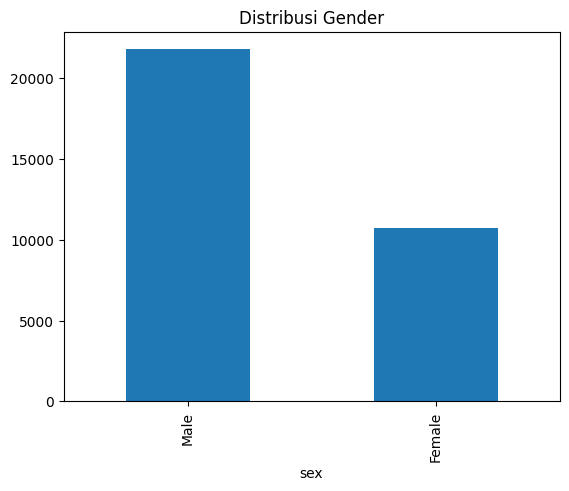

In [69]:
data['sex'].value_counts().plot(kind='bar')
plt.title('Distribusi Gender')
plt.show()

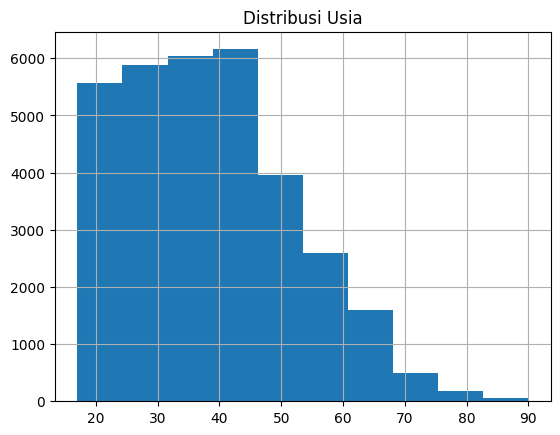

In [70]:
data['age'].hist()
plt.title('Distribusi Usia')
plt.show()

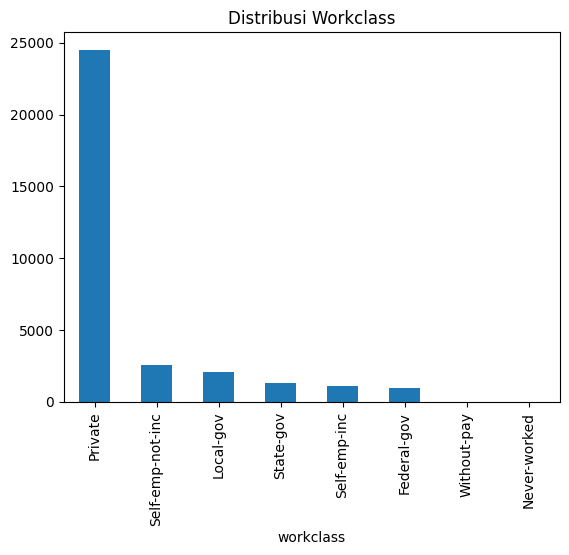

In [71]:
data['workclass'].value_counts().plot(kind='bar')
plt.title('Distribusi Workclass')
plt.show()

Selanjutnya kita akan melakukan pengecekan data, apakah target imbalance?

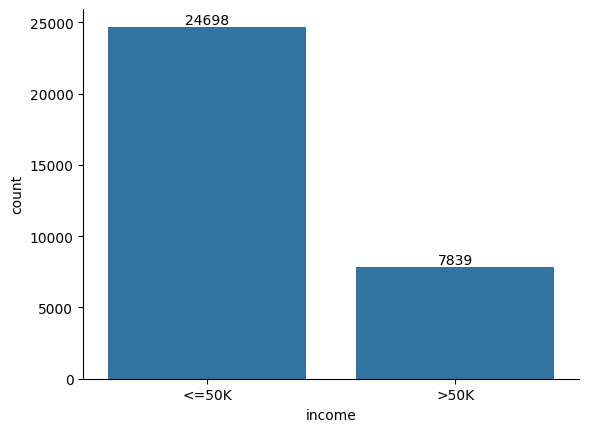

In [72]:
ax = sns.countplot(x='income', data=data)
for label in ax.containers:
    ax.bar_label(label)
sns.despine()
plt.show()

Berdasarkan grafik di atas, data target **tidak seimbang (imbalanced)**. Kelas `<=50K` berjumlah 24.698 data (sekitar 75,9%), sedangkan kelas `>50K` berjumlah 7.839 data (sekitar 24,1%), sehingga perbandingan kedua kelas sekitar 3 : 1.

Kondisi ini berpengaruh pada tahap pemodelan: akurasi saja bisa menyesatkan, karena model yang selalu menebak `<=50K` sudah mencapai akurasi sekitar 75,9%. Karena itu evaluasi model tidak hanya memakai akurasi, tetapi juga recall, F1-score, dan AUC-ROC pada kelas `>50K`.

**Periksa statistik deskriptif dari kumpulan data (rata-rata, distribusi, dll)**

In [73]:
# Melihat statistik deskriptif dari data
data.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


Dari kumpulan data yang diberikan, dapat dilihat bahwa terdapat 302 entri dan 6 kolom. Berikut adalah statistik deskriptif dari setiap variabel:

1. age: umur pasien, dengan rata-rata (mean) 54.42 tahun dan rentang antara 29 hingga 77 tahun.
2. trestbps: tekanan darah saat istirahat (resting blood pressure) dalam mmHg, dengan rata-rata 131.6 dan rentang antara 94 hingga 200.
3. chol: serum kolesterol dalam mg/dl, dengan rata-rata 246.5 dan rentang antara 126 hingga 564.
4. thalach: detak jantung maksimal yang dicapai selama tes olahraga, dengan rata-rata 149.57 dan rentang antara 71 hingga 202.
5. oldpeak: depresi ST (ST depression) relatif terhadap istirahat yang diinduksi oleh olahraga, dengan rata-rata 1.043 dan rentang antara 0 hingga 6.2.
6. target: variabel target yang menunjukkan keberadaan atau tidaknya penyakit jantung, dengan nilai 0 menunjukkan tidak adanya penyakit dan nilai 1 menunjukkan adanya penyakit.

Selanjutnya kita melihat distribusi data countinous.

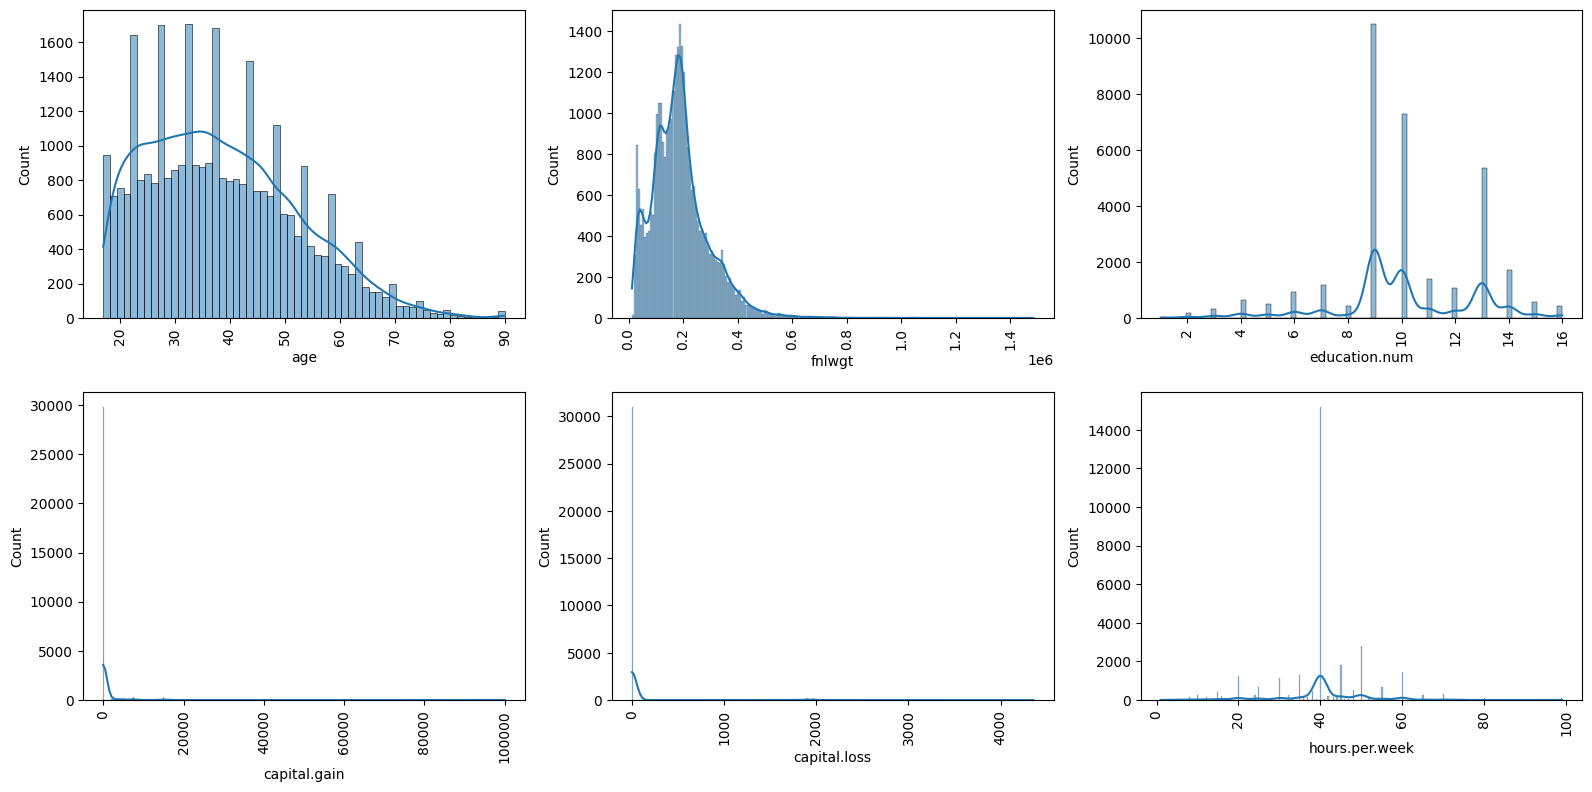

In [74]:
# Memvisualisasikan distribusi variabel numerical
numerical_col = data.select_dtypes(exclude=object)

plt.figure(figsize=(16,8))
for index, column in enumerate(numerical_col):
    plt.subplot(2,3,index+1)
    sns.histplot(data=numerical_col, x=column, kde=True)
    plt.xticks(rotation = 90)
plt.tight_layout(pad = 1.0)
plt.show()

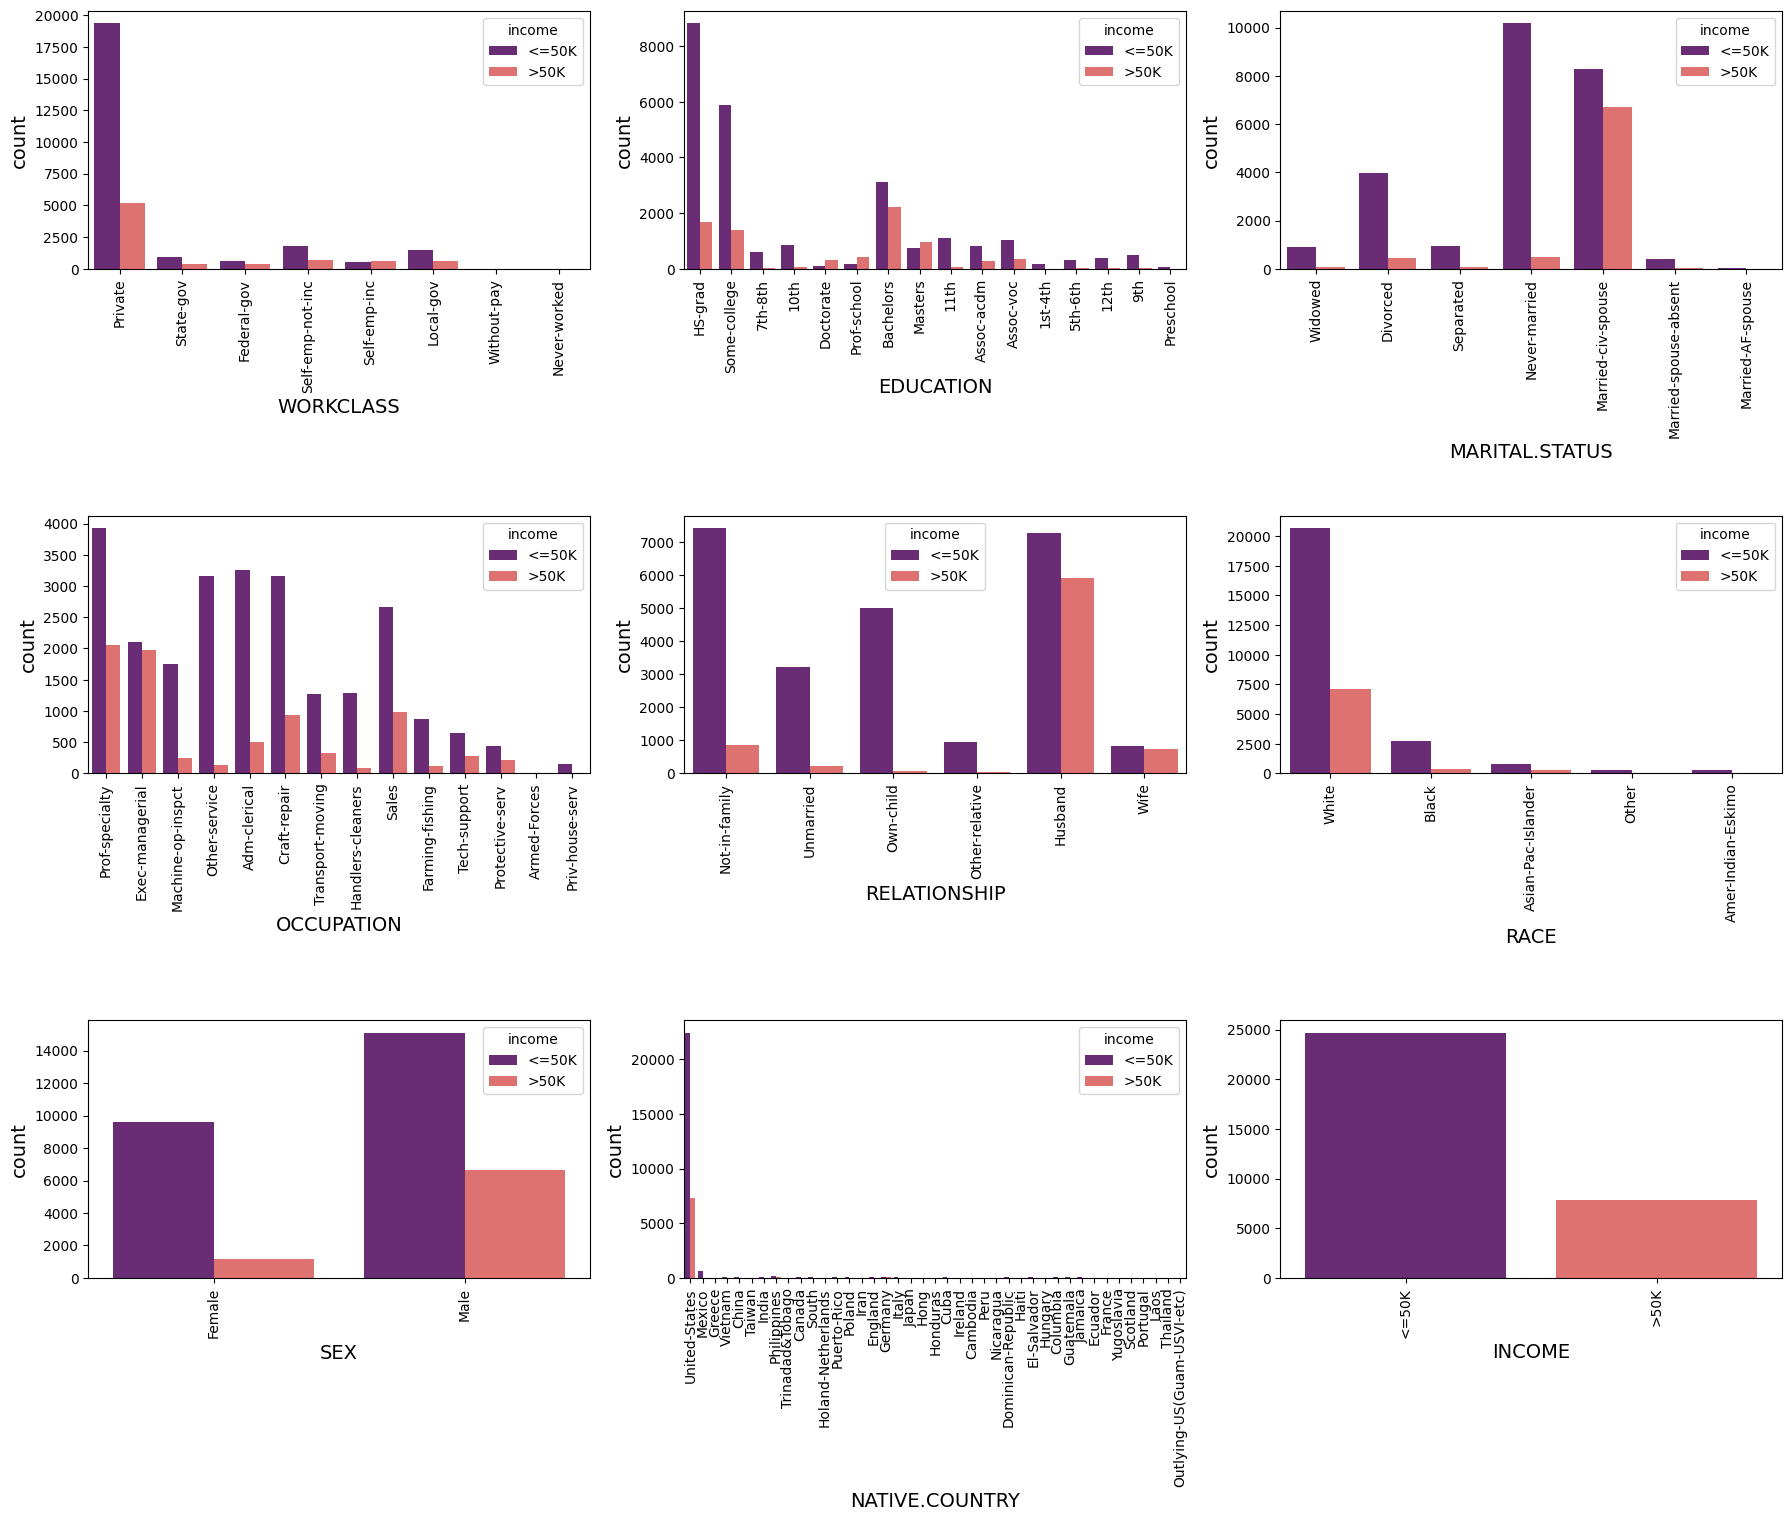

In [75]:
# Memvisualisasikan distribusi variabel kategorikal
categorical_col = data.select_dtypes(include=object)

plt.figure(figsize=(18,18))
for index, column in enumerate(categorical_col):
    plt.subplot(4, 3, index+1)
    sns.countplot(data=categorical_col, x=column, hue='income', palette='magma')
    plt.xlabel(column.upper(), fontsize=14)
    plt.ylabel("count", fontsize=14)
    plt.xticks(rotation=90)
plt.tight_layout(pad = 1.0)
plt.show()

Melihat korelasi antar feature.

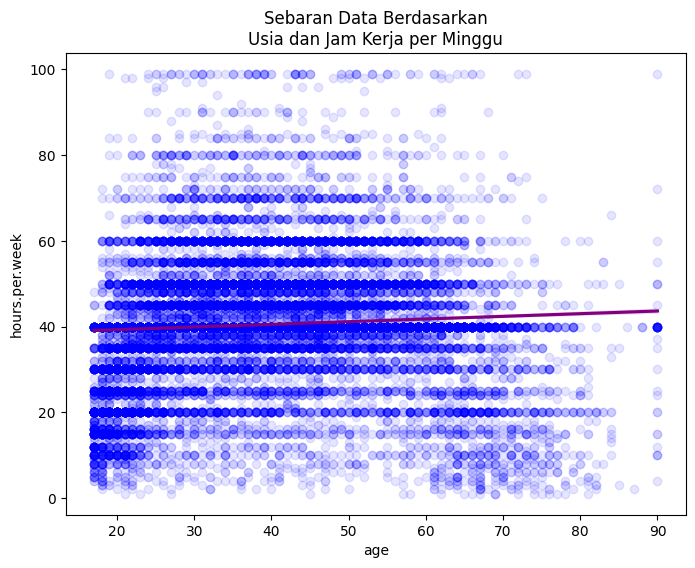

In [76]:
plt.figure(figsize = (8,6))
sns.regplot(x='age', y='hours.per.week', data=data, scatter_kws = {'color':'blue', 'alpha':0.1}, line_kws = {'color':'purple'})
plt.title('Sebaran Data Berdasarkan\nUsia dan Jam Kerja per Minggu')
plt.show()

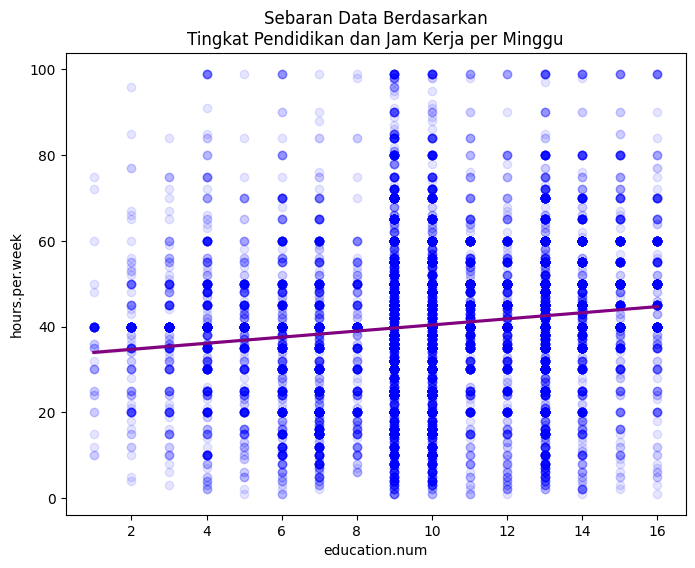

In [77]:
plt.figure(figsize = (8,6))
sns.regplot(x='education.num', y='hours.per.week', data=data, scatter_kws = {'color':'blue', 'alpha':0.1}, line_kws = {'color':'purple'})
plt.title('Sebaran Data Berdasarkan\nTingkat Pendidikan dan Jam Kerja per Minggu')
plt.show()

Simpulkan dari grafik yang kamu dapatkan?

In [78]:
# Simpan data yang sudah ada label
data.to_csv('data.csv')

# Melabeli kembali datanya
df = pd.read_csv('data.csv', index_col=0)

# 'education' dibuang karena redundan dengan 'education.num'
df = df.drop(columns=['education'])

# Dua kategori: replace manual seperti di notebook
df['sex'] = df['sex'].replace({'Male': 1, 'Female': 0})
df['income'] = df['income'].replace({'<=50K': 0, '>50K': 1})

# Kolom kategori banyak: diberi angka urut abjad, petanya disimpan
mappings = {}
for col in ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']:
    mappings[col] = {val: i for i, val in enumerate(sorted(df[col].unique()))}
    df[col] = df[col].replace(mappings[col])

print(mappings)
df.head()

{'workclass': {'Federal-gov': 0, 'Local-gov': 1, 'Never-worked': 2, 'Private': 3, 'Self-emp-inc': 4, 'Self-emp-not-inc': 5, 'State-gov': 6, 'Without-pay': 7}, 'marital.status': {'Divorced': 0, 'Married-AF-spouse': 1, 'Married-civ-spouse': 2, 'Married-spouse-absent': 3, 'Never-married': 4, 'Separated': 5, 'Widowed': 6}, 'occupation': {'Adm-clerical': 0, 'Armed-Forces': 1, 'Craft-repair': 2, 'Exec-managerial': 3, 'Farming-fishing': 4, 'Handlers-cleaners': 5, 'Machine-op-inspct': 6, 'Other-service': 7, 'Priv-house-serv': 8, 'Prof-specialty': 9, 'Protective-serv': 10, 'Sales': 11, 'Tech-support': 12, 'Transport-moving': 13}, 'relationship': {'Husband': 0, 'Not-in-family': 1, 'Other-relative': 2, 'Own-child': 3, 'Unmarried': 4, 'Wife': 5}, 'race': {'Amer-Indian-Eskimo': 0, 'Asian-Pac-Islander': 1, 'Black': 2, 'Other': 3, 'White': 4}, 'native.country': {'Cambodia': 0, 'Canada': 1, 'China': 2, 'Columbia': 3, 'Cuba': 4, 'Dominican-Republic': 5, 'Ecuador': 6, 'El-Salvador': 7, 'England': 8, 'Fr

,age,workclass,fnlwgt,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,3,77053,9,6,9,1,4,0,0,4356,40,38,0
1,82,3,132870,9,6,3,1,4,0,0,4356,18,38,0
2,66,3,186061,10,6,9,4,2,0,0,4356,40,38,0
3,54,3,140359,4,0,6,4,4,0,0,3900,40,38,0
4,41,3,264663,10,5,9,3,4,0,0,3900,40,38,0


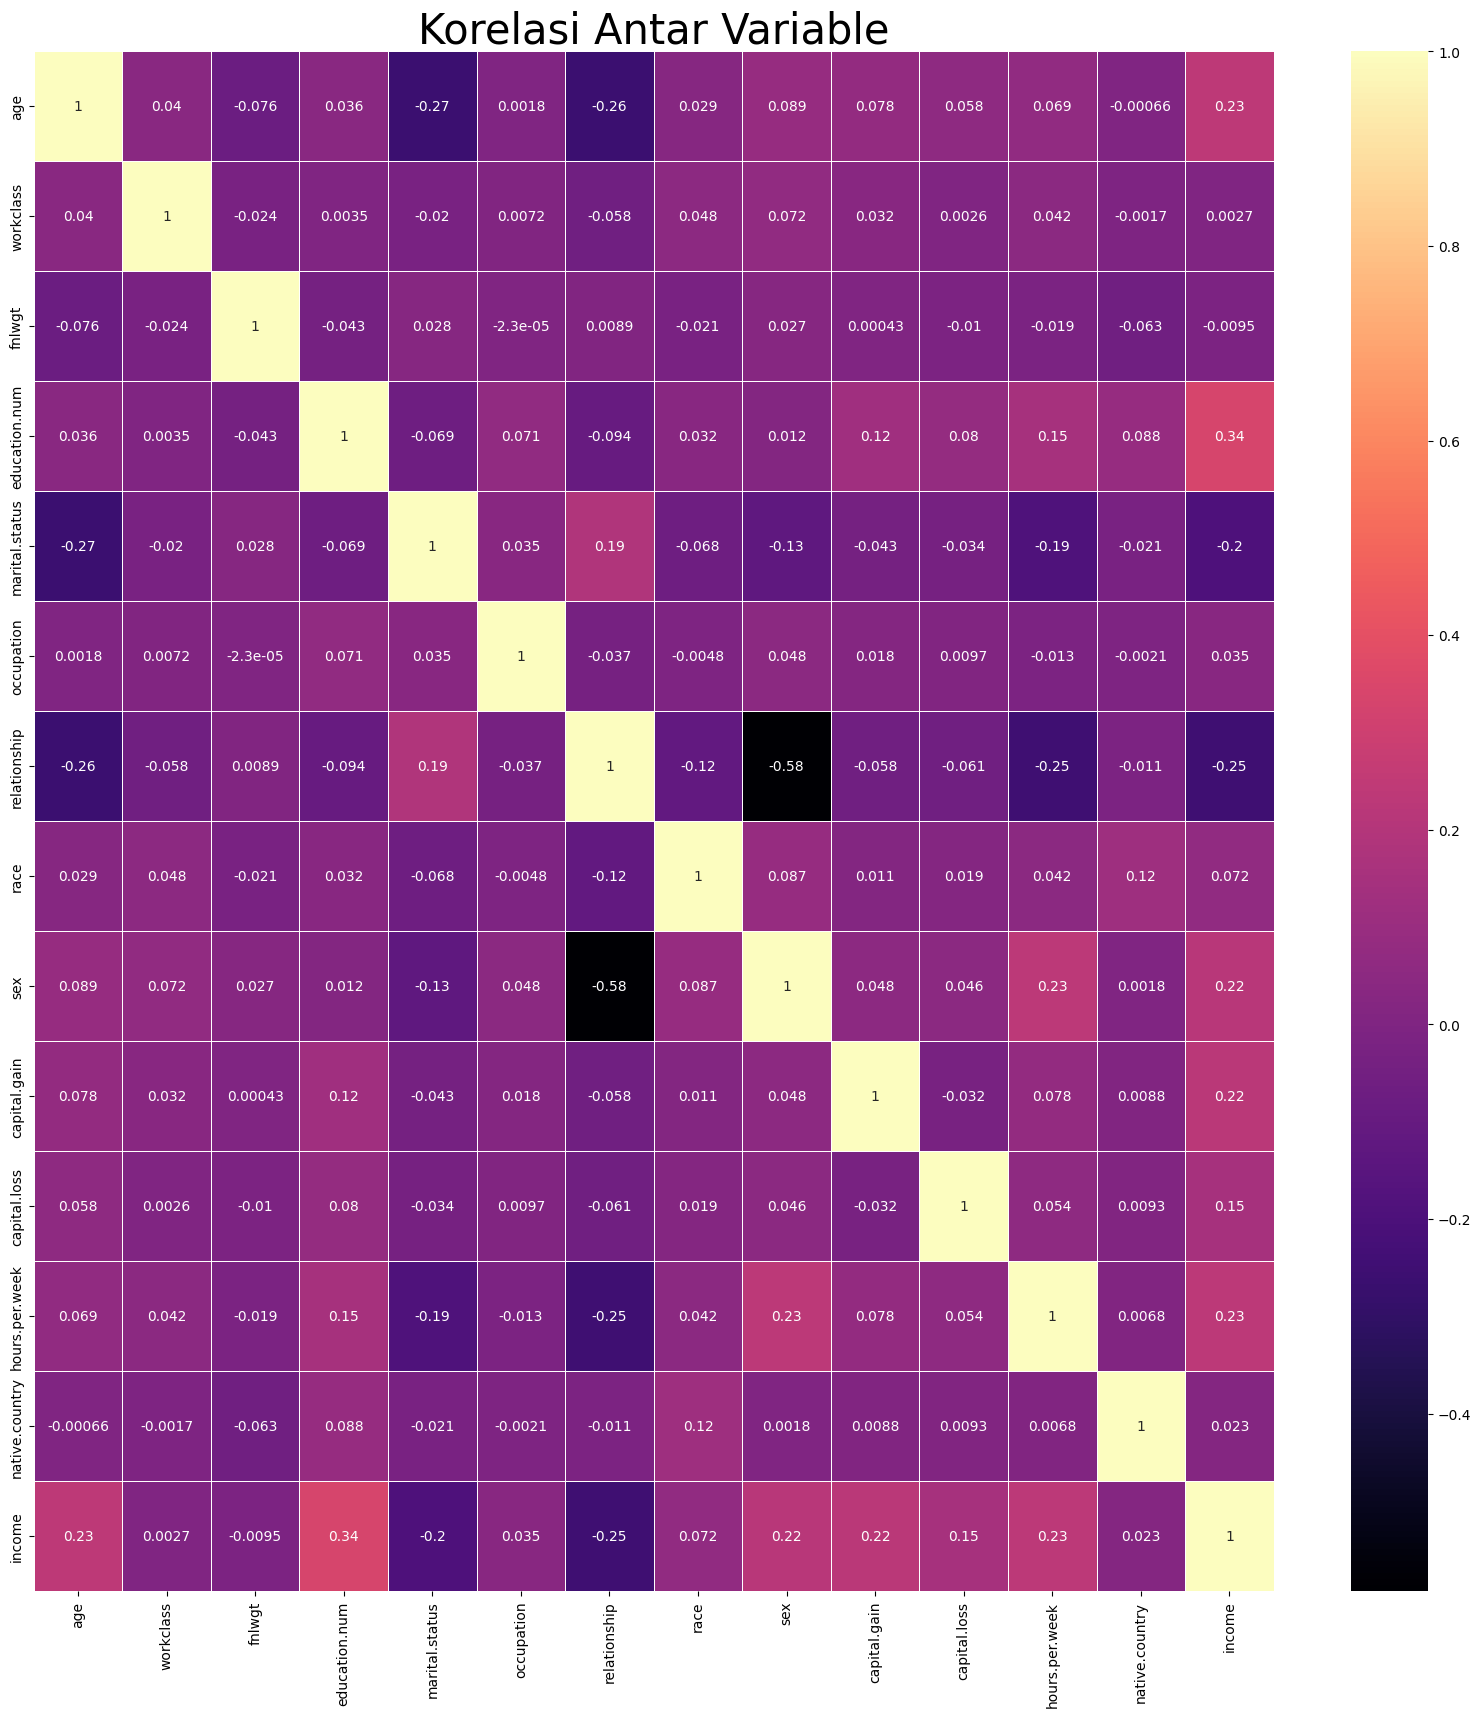

In [79]:
# melihat korelasi antar variable untuk mencari feature yang penting
plt.figure(figsize=(20,20))
cor = df.corr()
sns.heatmap(cor, annot=True, linewidth=.5, cmap="magma")
plt.title('Korelasi Antar Variable', fontsize = 30)
plt.show()

In [80]:
cor_matrix = df.corr()
cor_matrix

,age,workclass,fnlwgt,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
age,1.000000,0.040461,-0.076447,0.036224,-0.266137,0.001755,-0.263744,0.029116,0.088708,0.077676,0.057745,0.068515,-0.000659,0.234037
workclass,0.040461,1.000000,-0.024272,0.003503,-0.020430,0.007159,-0.057920,0.048349,0.071570,0.031506,0.002643,0.042200,-0.001669,0.002702
fnlwgt,-0.076447,-0.024272,1.000000,-0.043388,0.028123,-0.000023,0.008868,-0.021497,0.027089,0.000429,-0.010260,-0.018898,-0.063080,-0.009502
education.num,0.036224,0.003503,-0.043388,1.000000,-0.069161,0.070907,-0.094432,0.032011,0.012205,0.122664,0.079892,0.148422,0.088051,0.335272
marital.status,-0.266137,-0.020430,0.028123,-0.069161,1.000000,0.034855,0.185532,-0.067930,-0.129402,-0.043368,-0.034140,-0.190432,-0.020885,-0.199199
occupation,0.001755,0.007159,-0.000023,0.070907,0.034855,1.000000,-0.037429,-0.004807,0.047648,0.018006,0.009653,-0.012849,-0.002136,0.034516
relationship,-0.263744,-0.057920,0.008868,-0.094432,0.185532,-0.037429,1.000000,-0.116051,-0.582594,-0.057947,-0.061098,-0.248875,-0.010840,-0.250948
race,0.029116,0.048349,-0.021497,0.032011,-0.067930,-0.004807,-0.116051,1.000000,0.087472,0.011154,0.018913,0.041920,0.116850,0.071847
sex,0.088708,0.071570,0.027089,0.012205,-0.129402,0.047648,-0.582594,0.087472,1.000000,0.048489,0.045571,0.229187,0.001751,0.215969
capital.gain,0.077676,0.031506,0.000429,0.122664,-0.043368,0.018006,-0.057947,0.011154,0.048489,1.000000,-0.031639,0.078408,0.008777,0.223336


In [81]:
#Mengurutkan korelasi
cor_matrix['income'].sort_values()

relationship     -0.250948
marital.status   -0.199199
fnlwgt           -0.009502
workclass         0.002702
native.country    0.022853
occupation        0.034516
race              0.071847
capital.loss      0.150501
sex               0.215969
capital.gain      0.223336
hours.per.week    0.229658
age               0.234037
education.num     0.335272
income            1.000000
Name: income, dtype: float64

Korelasi `income` (target) dengan variabel lainnya. Korelasi positif berarti semakin tinggi nilai variabel, semakin besar kemungkinan berpenghasilan >50K. Korelasi negatif berarti sebaliknya.

1. education.num 0.335 (positif, sedang)
2. age 0.234 (positif, lemah-sedang)
3. hours.per.week 0.230 (positif, lemah-sedang)
4. capital.gain 0.223 (positif, lemah-sedang)
5. sex 0.216 (positif, lemah-sedang; Male = 1 lebih besar kemungkinannya >50K)
6. capital.loss 0.151 (positif, lemah)
7. race 0.072 (positif, sangat lemah)
8. occupation 0.035 (positif, sangat lemah)
9. native.country 0.023 (positif, sangat lemah)
10. workclass 0.003 (hampir nol)
11. fnlwgt -0.010 (hampir nol)
12. marital.status -0.199 (negatif, lemah)
13. relationship -0.251 (negatif, lemah-sedang)

Seluruh korelasi bernilai di bawah 0.35, sehingga tidak ada variabel yang berkorelasi kuat dengan `income`. Variabel `workclass`, `marital.status`, `occupation`, `relationship`, `race`, dan `native.country` merupakan kategori yang diberi angka berdasarkan urutan abjad, sehingga tanda (+/-) dan besar korelasinya hanya petunjuk kasar, bukan ukuran hubungan yang tepat. Nilai mendekati nol pada variabel tersebut tidak berarti variabel itu tidak berpengaruh.

Kesimpulan.

1. 'education.num', 'age', 'hours.per.week', 'capital.gain', dan 'sex' berkorelasi positif dengan 'income' (|r| antara 0.216 sampai 0.335).
2. 'relationship' berkorelasi negatif dengan 'income' (r = -0.251).
3. 'capital.loss', 'marital.status', 'race', 'occupation', 'native.country', 'workclass', dan 'fnlwgt' memiliki korelasi yang lebih lemah (|r| < 0.2) sehingga tidak dipilih.

Feature yang dipilih dengan batas |r| >= 0.2 yaitu: 'education.num', 'age', 'hours.per.week', 'capital.gain', 'sex', dan 'relationship' untuk dianalisa lebih lanjut.

In [82]:
variabel = ['education.num', 'age', 'hours.per.week', 'capital.gain', 'sex', 'relationship']
analyze = df[variabel]

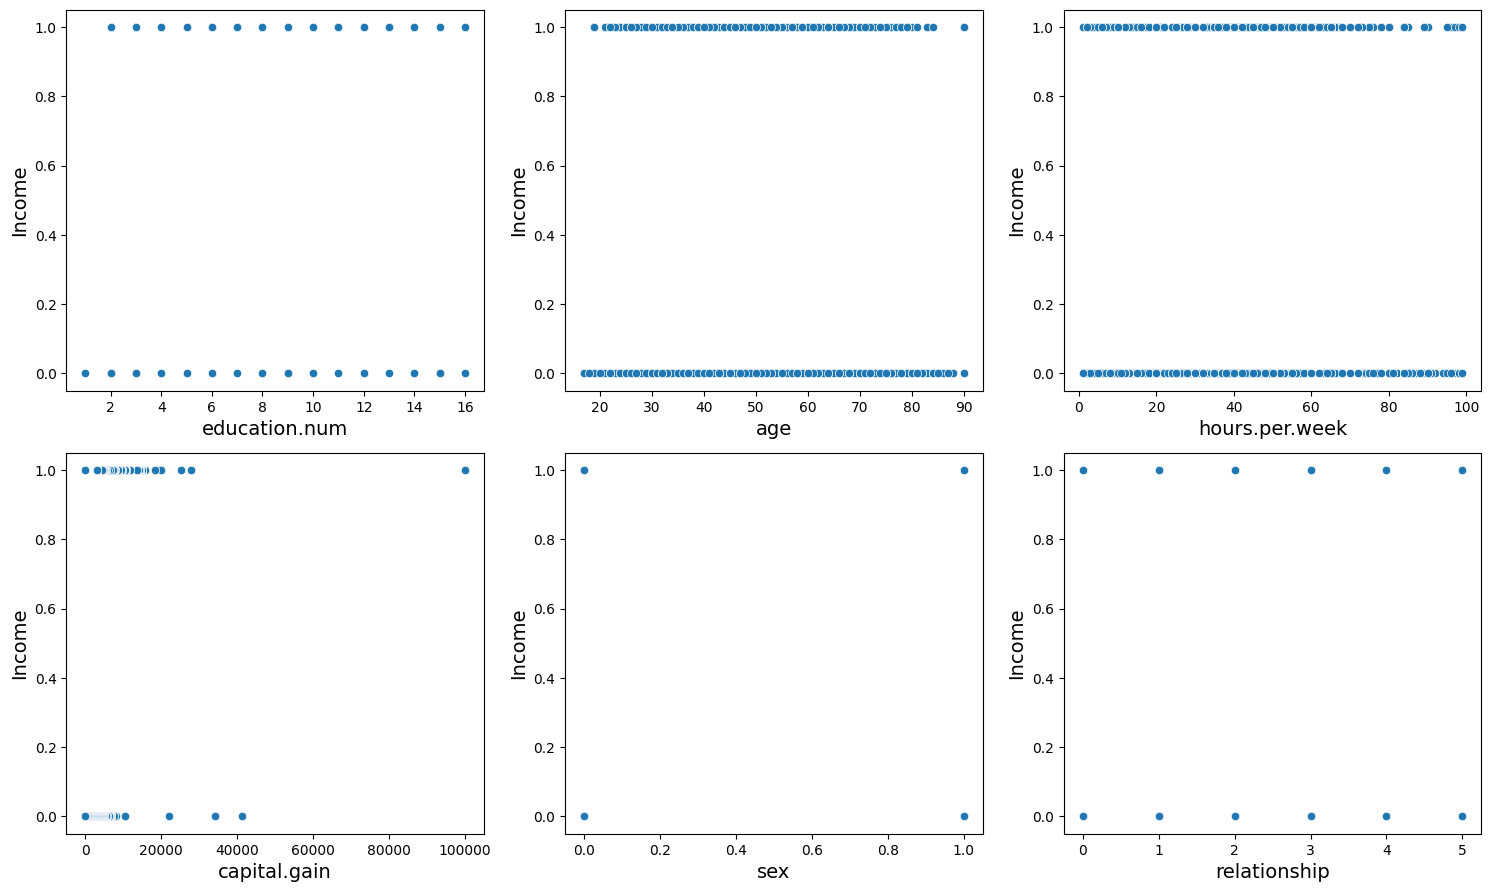

In [83]:
fig = plt.figure(figsize=(15,9))
for index in range(len(analyze.columns)):
    plt.subplot(2,3,index + 1)
    sns.scatterplot(x = analyze.iloc[:,index], y=df.income, data = analyze)
    plt.xlabel(analyze.columns[index], fontsize=14)
    plt.ylabel("Income", fontsize=14)

fig.tight_layout(pad = 1.0)

**Scaling data**

Scaling adalah suatu cara untuk membuat numerical data pada dataset memiliki rentang nilai (scale) yang sama. Tidak ada lagi satu variabel data yang mendominasi variabel data lainnya.

In [84]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop("income", axis=1))

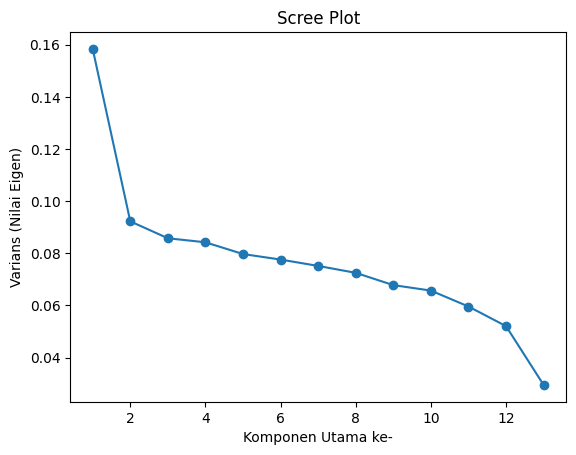

In [85]:
feature_number = len(X_scaled[0])
pca = PCA(n_components=feature_number)
pca.fit(X_scaled)

variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)

plt.plot(range(1, len(variance_ratio) + 1), variance_ratio, marker='o')
plt.xlabel('Komponen Utama ke-')
plt.ylabel('Varians (Nilai Eigen)')
plt.title('Scree Plot')
plt.show()

In [86]:
print(np.round(variance_ratio, 3))
print(np.round(cumulative_variance, 3))

[0.158 0.092 0.086 0.084 0.08  0.078 0.075 0.072 0.068 0.066 0.06  0.052
 0.029]
[0.158 0.251 0.336 0.421 0.5   0.578 0.653 0.725 0.793 0.859 0.918 0.971
 1.   ]


In [87]:
pca = PCA(n_components=10)
heart_data_reduced = pca.fit_transform(X_scaled)

print("Total varians terjelaskan:", round(pca.explained_variance_ratio_.sum(), 3))

Total varians terjelaskan: 0.859


In [88]:
feature_names = df.drop('income', axis=1).columns.to_list()
component_names = [f"PC{i+1}" for i in range(pca.n_components_)]

for component, component_name in zip(pca.components_, component_names):
    feature_indices = component.argsort()[::-1]
    retained_features = [feature_names[idx] for idx in feature_indices[:pca.n_components_]]
    print(f"{component_name}: {retained_features}")

PC1: ['relationship', 'marital.status', 'fnlwgt', 'occupation', 'native.country', 'workclass', 'capital.loss', 'capital.gain', 'race', 'education.num']
PC2: ['education.num', 'native.country', 'capital.gain', 'relationship', 'race', 'capital.loss', 'age', 'occupation', 'hours.per.week', 'workclass']
PC3: ['age', 'relationship', 'capital.loss', 'workclass', 'hours.per.week', 'capital.gain', 'race', 'native.country', 'fnlwgt', 'sex']
PC4: ['race', 'native.country', 'workclass', 'sex', 'marital.status', 'capital.loss', 'relationship', 'age', 'fnlwgt', 'hours.per.week']
PC5: ['capital.loss', 'education.num', 'occupation', 'hours.per.week', 'fnlwgt', 'sex', 'native.country', 'age', 'marital.status', 'relationship']
PC6: ['occupation', 'workclass', 'age', 'marital.status', 'capital.loss', 'sex', 'relationship', 'education.num', 'race', 'capital.gain']
PC7: ['workclass', 'capital.loss', 'hours.per.week', 'relationship', 'education.num', 'marital.status', 'fnlwgt', 'capital.gain', 'race', 'sex